# CNN-11 · Extra: diagnóstico por imagem de ECG (demonstração)

Notebook de ponta a ponta do extra, **sem treinar nada**: carrega os resultados e o modelo salvo. Para reproduzir os
números, os comandos estão no README (seção do extra).

**Problema:** triagem de ECGs impressos (12 derivações) em 4 classes: normal, batimento anormal, histórico de infarto e
infarto. O modelo é **apoio à decisão**: quem decide é o médico.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from cardio.config import FIGURES_DIR, RESULTS_DIR
from cardio_visual.config import IMAGES_DIR
from cardio_visual.data.preprocessing import get_transforms, load_image_splits, make_loaders
from cardio_visual.models.evaluate import evaluate_predictions, predict_loader
from cardio_visual.models.predict import FINAL_CHECKPOINT, load_checkpoint

NOMES = {"normal": "Normal", "batimento_anormal": "Batimento anormal",
         "historico_infarto": "Histórico de infarto", "infarto": "Infarto"}


def pct(x: float, casas: int = 0) -> str:
    return f"{x:.{casas}%}".replace(".", ",")


def num(x: float, casas: int = 2) -> str:
    return f"{x:.{casas}f}".replace(".", ",")

from cardio_visual.models.cv import CNN_CV_RESULTS_PATH, summarize
from cardio_visual.models.evaluate import summary_table
from cardio_visual.models.explain import desnormalizar
from cardio_visual.models.predict import AVISO, check_demo, predict_files

# os módulos do cardio_visual fixam o backend "Agg" (só arquivos); aqui queremos os gráficos dentro do notebook
%matplotlib inline

## 1. Dataset

In [2]:
origem = pd.read_csv(IMAGES_DIR / "origem.csv")
gabarito_path = IMAGES_DIR.parent / "demo_gabarito.csv"
splits = load_image_splits(save=False)
tabela = pd.DataFrame({
    "arquivos no zip": origem.groupby("classe")["copias"].sum(),
    "imagens únicas": origem.groupby("classe").size(),
    "treino": splits.train["classe"].value_counts(), "validação": splits.val["classe"].value_counts(),
    "teste": splits.test["classe"].value_counts(),
}).fillna(0).astype(int)
tabela["teste cego (demo)"] = pd.read_csv(gabarito_path)["classe"].value_counts().reindex(tabela.index).fillna(0).astype(int)
print(tabela.rename(index=NOMES).to_string())
print(f"\nO zip do Kaggle tem {int(tabela['arquivos no zip'].sum())} arquivos, mas só {int(tabela['imagens únicas'].sum())} "
      "imagens diferentes (o test/ original é cópia do train/). Usamos só as únicas, reservamos 1 por classe para o "
      "teste cego e dividimos o resto em 70/15/15. Detalhes: notebooks/cnn_01_eda_imagens.ipynb.")

                      arquivos no zip  imagens únicas  treino  validação  teste  teste cego (demo)
classe                                                                                            
Batimento anormal                 345             233     162         35     35                  1
Histórico de infarto              284              86      59         13     13                  1
Infarto                           351              30      21          4      4                  1
Normal                            396             142      98         21     22                  1

O zip do Kaggle tem 1376 arquivos, mas só 491 imagens diferentes (o test/ original é cópia do train/). Usamos só as únicas, reservamos 1 por classe para o teste cego e dividimos o resto em 70/15/15. Detalhes: notebooks/cnn_01_eda_imagens.ipynb.


## 2. Pré-processamento: só a grade do traçado

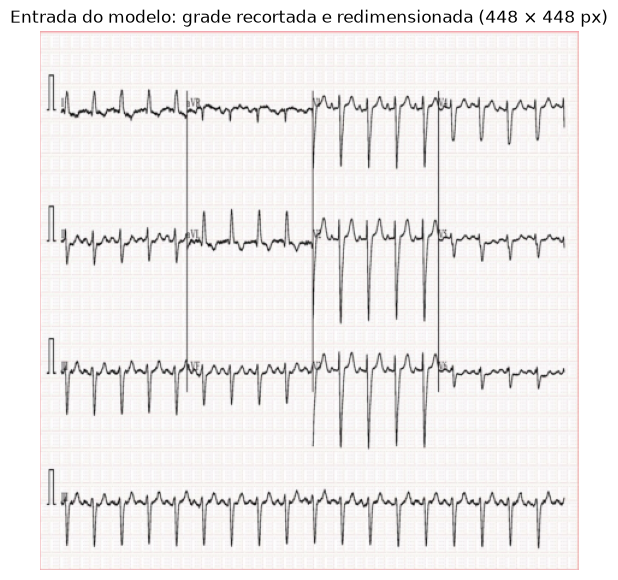

O recorte tira o cabeçalho e o rodapé (ID do paciente, data, hora e frequência cardíaca impressos), que não são o ECG e poderiam virar atalho. O aumento de dados do treino não gira a imagem: inverter um ECG cria um traçado que não existe.


In [3]:
exemplo = splits.val["caminho"].iloc[0]
ck = load_checkpoint(FINAL_CHECKPOINT)
with Image.open(exemplo) as img:
    x = get_transforms(train=False, size=ck["image_size"])(img.convert("RGB"))
plt.figure(figsize=(7, 7)); plt.imshow(desnormalizar(x)); plt.axis("off")
plt.title(f"Entrada do modelo: grade recortada e redimensionada ({ck['image_size']} × {ck['image_size']} px)"); plt.show()
print("O recorte tira o cabeçalho e o rodapé (ID do paciente, data, hora e frequência cardíaca impressos), que não são o ECG "
      "e poderiam virar atalho. O aumento de dados do treino não gira a imagem: inverter um ECG cria um traçado que não existe.")

## 3. Comparação dos modelos (validação e validação cruzada)

In [4]:
comparacao = summary_table(RESULTS_DIR / "cnn_val_results.csv")[["modelo", "acuracia", "f1_macro", "recall_macro",
                                                                "f1_macro_ic_baixo", "f1_macro_ic_alto", "epocas",
                                                                "tempo_treino_s"]]
print("Validação (um split, ~70 imagens):"); print(comparacao.round(3).to_string(index=False))
cv = pd.read_csv(CNN_CV_RESULTS_PATH)
print("\nValidação cruzada (5 folds sobre treino + validação), média ± desvio:")
for nome, grupo in cv.groupby("modelo"):
    r = summarize(grupo.drop(columns=["modelo", "arquitetura", "image_size", "freeze"]))
    print(f"  {nome}: F1 macro {num(r.loc['f1_macro', 'media'])} ± {num(r.loc['f1_macro', 'desvio'])} | "
          f"recall infarto {num(r.loc['recall_infarto', 'media'])} ± {num(r.loc['recall_infarto', 'desvio'])}")

Validação (um split, ~70 imagens):
         modelo  acuracia  f1_macro  recall_macro  f1_macro_ic_baixo  f1_macro_ic_alto  epocas  tempo_treino_s
   resnet18_448     0.904     0.849         0.830              0.657             0.963      12        1512.787
   resnet18_224     0.863     0.786         0.745              0.582             0.915       8         346.051
cnn_simples_224     0.616     0.398         0.434              0.328             0.497      11         251.580

Validação cruzada (5 folds sobre treino + validação), média ± desvio:
  cnn_simples_224: F1 macro 0,60 ± 0,09 | recall infarto 0,40 ± 0,14
  resnet18_224: F1 macro 0,83 ± 0,05 | recall infarto 0,72 ± 0,11


## 4. Avaliação final no teste (uso único)

              classe  precision  recall    f1  suporte
   Batimento anormal      0.944   0.971 0.958       35
Histórico de infarto      0.867   1.000 0.929       13
             Infarto      1.000   0.500 0.667        4
              Normal      1.000   0.955 0.977       22

4 classes: acurácia 0,95 | F1 macro 0,88 (IC 95%: 0,70 a 0,99)
Binário (normal × alterado): recall 1,00 | especificidade 0,95 | AUC 1,00


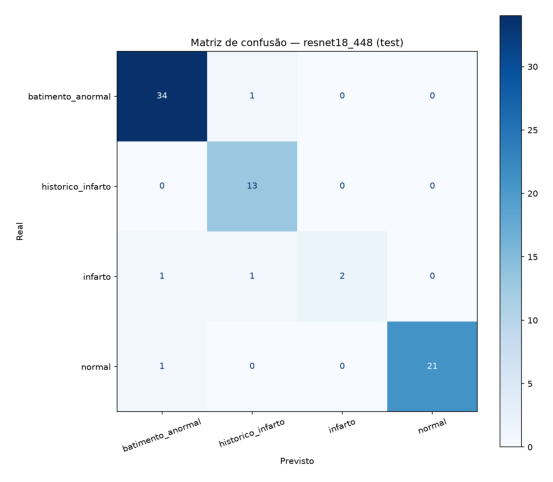

In [5]:
teste = pd.read_csv(RESULTS_DIR / "cnn_test_results.csv").iloc[0]
por_classe = pd.read_csv(RESULTS_DIR / "cnn_test_por_classe.csv")
print(por_classe.assign(classe=por_classe["classe"].map(NOMES)).round(3).to_string(index=False))
print(f"\n4 classes: acurácia {num(teste['acuracia'])} | F1 macro {num(teste['f1_macro'])} "
      f"(IC 95%: {num(teste['f1_macro_ic_baixo'])} a {num(teste['f1_macro_ic_alto'])})")
print(f"Binário (normal × alterado): recall {num(teste['recall_alterado'])} | especificidade {num(teste['especificidade'])} | "
      f"AUC {num(teste['auc_binaria'])}")
cm = FIGURES_DIR / f"cnn_cm_{teste['modelo']}_test.png"
plt.figure(figsize=(7, 6)); plt.imshow(Image.open(cm)); plt.axis("off"); plt.show()

## 5. Interpretação (Grad-CAM)

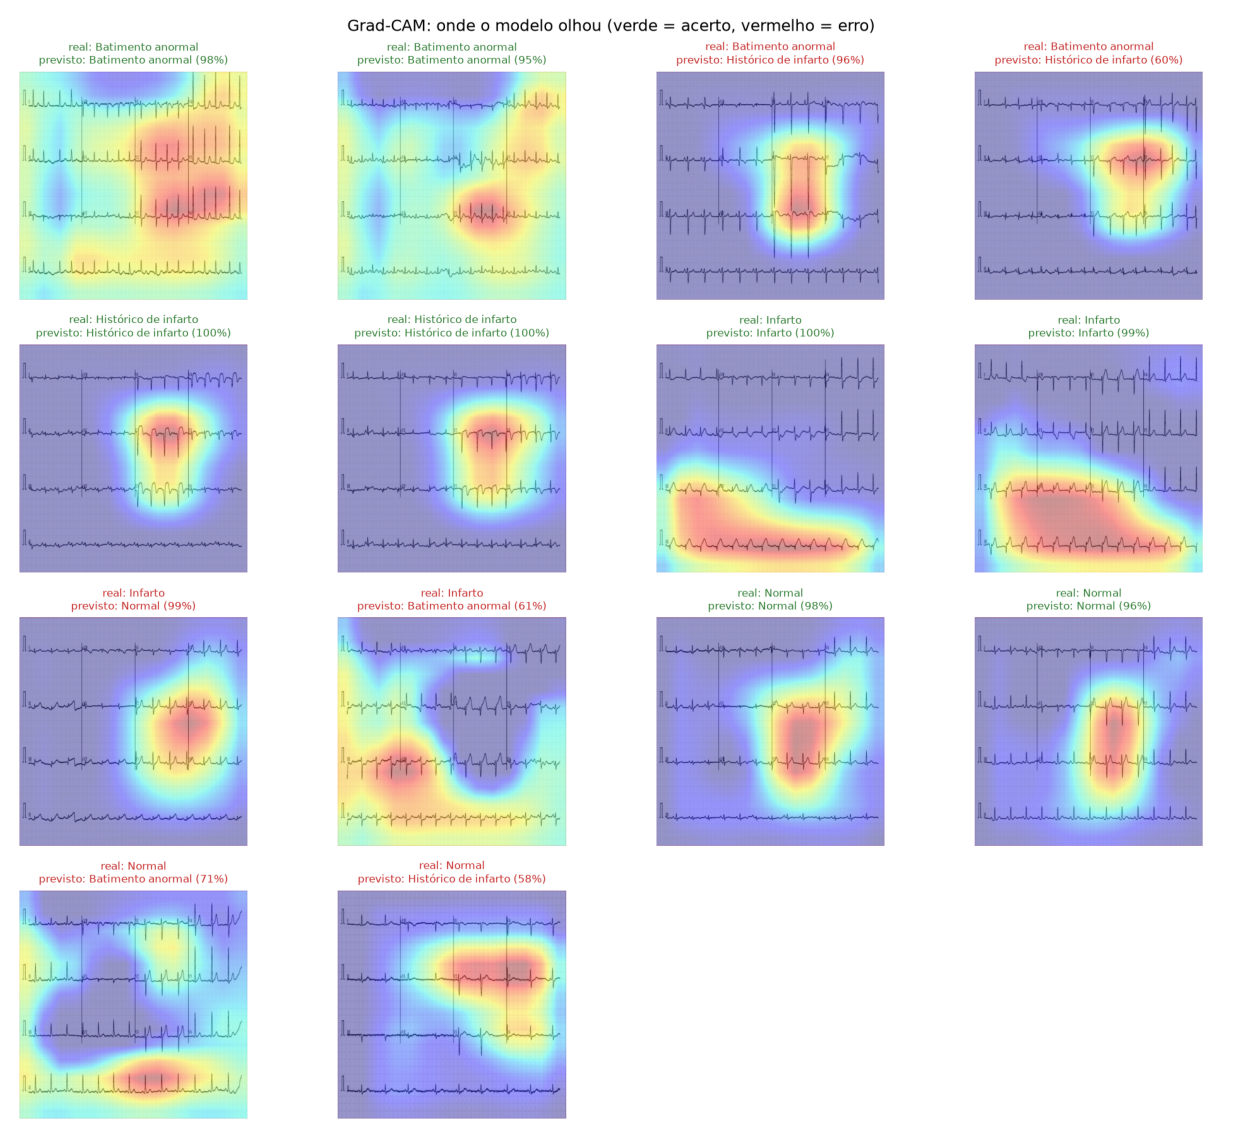

Detalhes e a medida de quanto o calor cai sobre o traçado: notebooks/cnn_02_interpretacao.ipynb.


In [6]:
plt.figure(figsize=(16, 16)); plt.imshow(Image.open(FIGURES_DIR / "cnn_gradcam_val.png")); plt.axis("off"); plt.show()
print("Detalhes e a medida de quanto o calor cai sobre o traçado: notebooks/cnn_02_interpretacao.ipynb.")

## 6. Teste cego (4 imagens nunca vistas pelo modelo)

Uma imagem de cada classe foi sorteada e separada **antes** do treino (`data/demo/ecg_1.jpg` a `ecg_4.jpg`). Primeiro o
modelo classifica sem ver a resposta; depois conferimos com o gabarito. É o mesmo que `python -m cardio_visual.models.predict
--demo` e `--demo --gabarito`.

In [7]:
demo = sorted((IMAGES_DIR.parent / "demo").glob("ecg_*.jpg"))
previsoes = predict_files(ck, demo)
print(previsoes[["arquivo", "classe_prevista", "probabilidade", "prob_alterado"]]
      .assign(classe_prevista=lambda d: d["classe_prevista"].map(NOMES)).round(3).to_string(index=False))

  arquivo      classe_prevista  probabilidade  prob_alterado
ecg_1.jpg               Normal          0.995          0.005
ecg_2.jpg              Infarto          0.614          0.776
ecg_3.jpg    Batimento anormal          0.978          0.998
ecg_4.jpg Histórico de infarto          0.994          0.999


In [8]:
conferido = check_demo(previsoes, gabarito_path)
print(conferido[["arquivo", "classe_prevista", "classe_real", "probabilidade", "acertou"]]
      .assign(classe_prevista=lambda d: d["classe_prevista"].map(NOMES), classe_real=lambda d: d["classe_real"].map(NOMES))
      .round(3).to_string(index=False))
print(f"\nAcertos: {int(conferido['acertou'].sum())} de {len(conferido)}. Com 4 imagens isso é uma demonstração, não uma "
      "medida de desempenho (essa é a do teste, na seção 4).")
print(AVISO)

  arquivo      classe_prevista          classe_real  probabilidade  acertou
ecg_1.jpg               Normal               Normal          0.995     True
ecg_2.jpg              Infarto              Infarto          0.614     True
ecg_3.jpg    Batimento anormal    Batimento anormal          0.978     True
ecg_4.jpg Histórico de infarto Histórico de infarto          0.994     True

Acertos: 4 de 4. Com 4 imagens isso é uma demonstração, não uma medida de desempenho (essa é a do teste, na seção 4).
Apoio à decisão: o modelo não substitui a avaliação do médico, que tem a palavra final.


## 7. Conclusão

In [9]:
print(f"""- O dataset tem só {int(tabela['imagens únicas'].sum())} ECGs diferentes e 30 de infarto: o resultado tem incerteza grande
  (IC 95% do F1 macro no teste: {num(teste['f1_macro_ic_baixo'])} a {num(teste['f1_macro_ic_alto'])}).
- No teste, o F1 macro foi {num(teste['f1_macro'])}; na visão de triagem (normal × alterado), o modelo sinaliza
  {pct(teste['recall_alterado'])} dos ECGs alterados com especificidade de {pct(teste['especificidade'])}.
- O modelo pode ajudar a **priorizar** a leitura de ECGs, nunca a dispensá-la: dados de um único hospital, ECG impresso
  (não o sinal original) e classes pequenas. {AVISO}""")

- O dataset tem só 491 ECGs diferentes e 30 de infarto: o resultado tem incerteza grande
  (IC 95% do F1 macro no teste: 0,70 a 0,99).
- No teste, o F1 macro foi 0,88; na visão de triagem (normal × alterado), o modelo sinaliza
  100% dos ECGs alterados com especificidade de 95%.
- O modelo pode ajudar a **priorizar** a leitura de ECGs, nunca a dispensá-la: dados de um único hospital, ECG impresso
  (não o sinal original) e classes pequenas. Apoio à decisão: o modelo não substitui a avaliação do médico, que tem a palavra final.
